# 21 · An agent registry: the catalogue callers search
Level L4 · Part 4 · core · ~25 min · builds on 19, 20

## Goal
Keep a catalogue of agents: each one registered with its base, version, owner and skills, checked for health, and allowed or refused by an
allow-list. A caller searches the catalogue by skill. An agent that stops answering is removed from search. The catalogue is a LangGraph
store, so it needs no extra service. This lesson makes no model call.

## Why it matters
Discovery (lesson 20) finds one agent at one address. A company has many agents, and a caller should not know them all. A registry answers
three questions at once: which agents offer this skill, which of them are allowed to be called, and which are working right now. Without it,
a dead agent is still called, and an agent nobody approved answers customers.

| Discovery only | With a registry |
|---|---|
| The caller knows the address it was given | The caller searches by skill |
| A dead agent is found and called | A failing agent is removed from search |
| Any agent with a card can be called | An agent must be registered and allowed |

**What it makes easy:** one place to see every agent, its version and its health. **When you don't need it:** a single agent in one service.

## The idea
A **registry** is a table of entries keyed by agent name. Each entry holds the base address, the version, the owner, the skills and the status.
**Register** adds an entry after a health check. **Search** looks for entries by skill, only where the entry is allowed and healthy. **Health**
checks an entry again and removes it when it fails. The registry is data; the checks are code.

## Picture
The next cell calls `show_mermaid`, a helper in the topic folder (`graph_view.py`) that draws a flowchart from the Mermaid text you pass it.
Read the diagram from the top: publish, register, search, allow-list, then the periodic health check.

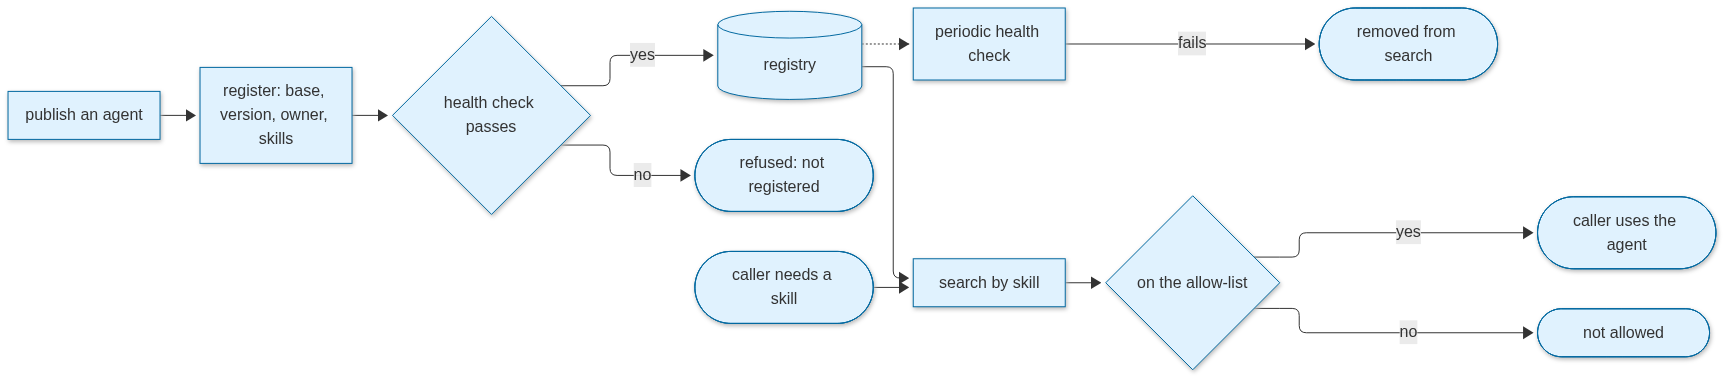

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  P["publish an agent"] --> R["register: base, version, owner, skills"]
  R --> H{"health check passes"}
  H -->|yes| L[("registry")]
  H -->|no| X(["refused: not registered"])
  Q(["caller needs a skill"]) --> S["search by skill"]
  L --> S
  S --> A{"on the allow-list"}
  A -->|yes| C(["caller uses the agent"])
  A -->|no| N(["not allowed"])
  L -.-> HC["periodic health check"] -->|fails| D(["removed from search"])
  classDef code fill:#e0f2fe,stroke:#0369a1
  class P,R,H,L,X,Q,S,A,C,N,HC,D code
""")

## Step by step

**Step 1 · the agents to publish (no call).** The two agents from lesson 20 are read from its folder. A third agent, `refunds-agent`, is
written to this lesson's own folder: its card is fine, but it is not approved for customers. A fourth entry, `claims-agent`, points at a
folder that does not exist, so the health check has something to refuse.

In [2]:
import json
from pathlib import Path

from langgraph.store.memory import InMemoryStore  # LangGraph's in-memory store: a key-value table grouped by namespace

ROOT = Path("../../../data/lg20/agents")  # written by lesson 20
MINE = Path("../../../data/21/agents")  # this lesson's own agents
for folder, name, skill in [(ROOT, "orders-agent", "order_status"), (ROOT, "policy-agent", "policy_answer"),
                            (MINE, "refunds-agent", "refund_order")]:
    base = folder / name / ".well-known"
    if not (base / "agent-card.json").exists():
        base.mkdir(parents=True, exist_ok=True)
        (base / "agent-card.json").write_text(json.dumps({
            "name": name, "description": name, "skills": [{"id": skill, "description": name}], "auth": "none"}))

PUBLISHED = [
    {"name": "orders-agent", "base": str(ROOT / "orders-agent"), "version": "1.2.0", "owner": "orders-team"},
    {"name": "policy-agent", "base": str(ROOT / "policy-agent"), "version": "2.0.1", "owner": "policy-team"},
    {"name": "refunds-agent", "base": str(MINE / "refunds-agent"), "version": "0.1.0", "owner": "refunds-team"},
    {"name": "claims-agent", "base": str(MINE / "claims-agent"), "version": "0.3.0", "owner": "claims-team"},  # folder missing
]
ALLOW_LIST = {"orders-agent", "policy-agent"}  # refunds-agent is healthy but not approved for customer traffic
print(len(PUBLISHED), "entries published; allowed:", sorted(ALLOW_LIST))

4 entries published; allowed: ['orders-agent', 'policy-agent']


**Step 2 · the registry and its checks (no call).** The registry is a LangGraph store under the namespace `("registry",)`. `health` reads the
card at the base; if the card is there and has skills, the agent is healthy. `register` runs the health check first, so a broken agent is never
written. `search` returns only healthy, allowed entries that offer the skill.

In [3]:
REGISTRY = InMemoryStore()
NS = ("registry",)


def health(base: str) -> tuple[bool, str]:
    card_path = Path(base) / ".well-known" / "agent-card.json"
    if not card_path.exists():
        return False, "no card at the base"
    card = json.loads(card_path.read_text())
    return (True, "card found") if card.get("skills") else (False, "the card lists no skills")


def register(entry: dict) -> str:
    ok, why = health(entry["base"])
    if not ok:
        return f"refused {entry['name']}: {why}"
    card = json.loads((Path(entry["base"]) / ".well-known" / "agent-card.json").read_text())
    REGISTRY.put(NS, entry["name"], entry | {"skills": [s["id"] for s in card["skills"]], "status": "healthy"})
    return f"registered {entry['name']} {entry['version']}"


def search(skill: str) -> list[dict]:
    hits = []
    for item in REGISTRY.search(NS):
        entry = item.value
        if skill in entry["skills"] and entry["status"] == "healthy" and entry["name"] in ALLOW_LIST:
            hits.append({"name": entry["name"], "version": entry["version"], "owner": entry["owner"]})
    return hits


for entry in PUBLISHED:
    print(register(entry))

registered orders-agent 1.2.0
registered policy-agent 2.0.1
registered refunds-agent 0.1.0
refused claims-agent: no card at the base


**Step 3 · search by skill (no call).** The caller asks for `policy_answer`. It gets the policy agent, with its version and owner. The
`refund_order` skill returns nothing: `refunds-agent` offers it and is healthy, but it is not on the allow-list.

In [4]:
print("policy_answer ->", search("policy_answer"))
print("order_status  ->", search("order_status"))
print("refund_order  ->", search("refund_order"))
print("refunds-agent status in the registry:", REGISTRY.get(NS, "refunds-agent").value["status"])

policy_answer -> [{'name': 'policy-agent', 'version': '2.0.1', 'owner': 'policy-team'}]
order_status  -> [{'name': 'orders-agent', 'version': '1.2.0', 'owner': 'orders-team'}]
refund_order  -> []
refunds-agent status in the registry: healthy


**Step 4 · a health check that fails later (no call).** The orders agent is taken down: its card is moved aside. The next health check finds
no card, removes the orders agent from the registry, and search no longer returns it. The caller is not sent to a dead address.

In [5]:
import os


def run_health_checks() -> list[str]:
    report = []
    for item in list(REGISTRY.search(NS)):
        entry = item.value
        ok, why = health(entry["base"])
        if not ok:
            REGISTRY.delete(NS, entry["name"])  # removed from search; a re-register brings it back
            report.append(f"removed {entry['name']}: {why}")
    return report


os.rename(ROOT / "orders-agent" / ".well-known" / "agent-card.json", ROOT / "orders-agent" / "card.bak")  # take it down
print(run_health_checks())
print("order_status  ->", search("order_status"))
os.rename(ROOT / "orders-agent" / "card.bak", ROOT / "orders-agent" / ".well-known" / "agent-card.json")  # bring it back for the next run

['removed orders-agent: no card at the base']
order_status  -> []


## At work
- A registry is the company's list of agents: who owns each one, which version is live, and which may take customer traffic. Teams review
  changes to it like a change to a database schema → lesson 34 (security and guardrails).
- An allow-list is the default answer: an agent is refused unless listed. A new agent is not reachable until someone approves it.
- Health checks run on a schedule, not only at registration. An agent that was healthy yesterday can be broken today → lesson 35 (reliability).

## What just happened
- Step 2: three entries registered (`orders-agent`, `policy-agent`, `refunds-agent`), and `claims-agent` refused because it had no card.
- Step 3: `policy_answer` found one agent, `policy-agent` 2.0.1. `refund_order` found nothing, although `refunds-agent` is healthy.
- Step 4: the health sweep removed `orders-agent`, so `order_status` now returns an empty list.

## Common mistakes
1. **A registry with no health check.** Every dead agent is still in search. Check on register and on a schedule. The cell below shows
   the real error a check-less register hits when it reads the card of `claims-agent`.
2. **An allow-list that defaults to yes.** An agent nobody listed should be refused, not served. Step 3 shows the default done right.
3. **Searching by name.** Callers ask for skills. Name is for people; skill is what the caller needs. Searching by name finds nothing.

In [6]:
try:
    json.loads((Path(PUBLISHED[3]["base"]) / ".well-known" / "agent-card.json").read_text())  # mistake 1: no check, just read
except FileNotFoundError as error:
    print(f"mistake 1: {type(error).__name__}: {str(error).splitlines()[0]}")
print("mistake 3, by name ->", search("orders-agent"))

mistake 1: FileNotFoundError: [Errno 2] No such file or directory: '../../../data/21/agents/claims-agent/.well-known/agent-card.json'
mistake 3, by name -> []


## Try it
Write `count_healthy(registry_items)` that returns how many entries have status `"healthy"`. Test it on the entries left in `REGISTRY` after Step 4. No
model call is needed.

In [7]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [8]:
def count_healthy(items) -> int:
    return sum(1 for item in items if item.value["status"] == "healthy")


print(count_healthy(REGISTRY.search(NS)))  # 2: policy-agent and refunds-agent remain; orders-agent was removed in Step 4

2


## Key terms
- **Registry** — the catalogue of agents, with each agent's base address, version, owner, skills and status.
- **Health check** — a test run at registration and again on a schedule; an agent without a valid card fails it.
- **Allow-list** — the list of agents approved for callers; an agent not on it is refused, even if it is healthy.
- **Skill** — what an agent offers, named in its card; callers search by skill, not by agent name.

## Recap
- A registry is a catalogue of agents with their base, version, owner and skills.
- An entry is written only after a health check, and search returns only healthy, allowed entries.
- A failing agent is removed from search, and a caller is never sent to a dead address.

**Interview:** "A team wants a new agent to be callable from the support desk. What must be true before it is reachable?" Strong answer: "It must
publish a card, pass a health check at registration, and be on the allow-list. Its health is checked again on a schedule, and it leaves search
when it fails."